# CMSE 202 Project Final Report
### Group Names : Omar Abdulwahhab , Mohammed Alsayegh , Mint Menakanit, Prisha Kuma , Sai Palaka

##                             *What Makes a Song Popular on Spotify?*

## Introduction
Music streaming is a huge part of our life, and Spotify is one of the most popular platforms. Every day, millions of users listen to songs, creating data that reflects what people like. But a big question remains: what actually makes a song popular on Spotify? Is it the mood of the song, the energy, the artist's fame, or something else entirely? In this project, we will investigate which musical features are most strongly associated with a song's popularity score on Spotify. Features like danceability, energy, loudness, tempo, and valence (the positivity of the song) might play a role. We want to explore these relationships and understand whether they can help predict popularity. This detailed look will help answer whether we can turn musical attributes into measurable predictors of success.


## Methods

For this project, we used the “Spotify Tracks Dataset (1921–2020)” from Kaggle, which contains over 160,000 songs collected through Spotify’s Web API. Each song includes audio features such as danceability, energy, loudness, tempo, valence, speechiness, and popularity (a score ranging from 0 to 100). We analyzed this dataset to explore which features are most related to popularity and whether we could predict popularity using these features. To perform our analysis, we used Python libraries like pandas for loading and cleaning the data, seaborn and matplotlib for creating visualizations such as correlation heatmaps and bar plots, and scikit-learn for building a simple Linear Regression model. Our workflow started with importing and cleaning the dataset to remove missing or invalid values. Next, we conducted exploratory data analysis (EDA) to understand the distribution of features and to identify relationships with popularity. We then trained a linear regression model using key features (e.g., danceability, energy, tempo, and loudness) to predict a song’s popularity score. Finally, we evaluated the model’s performance using the Mean Squared Error (MSE) and examined the regression coefficients to interpret which audio features have the strongest influence on popularity.

### We will import all the Python tools we need. We are using pandas to work with the dataset, matplotlib and seaborn to make charts, and scikit-learn to build a simple model. We then load data.csv (Spotify dataset) and display the first 5 rows to see what it looks like.

In [5]:
#Libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [17]:
data = pd.read_csv("data.csv")
data.head(5)

,valence,year,acousticness,artists,danceability,energy,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
0,0.0594,1921,0.982,"['Sergei Rachmaninoff', 'James Levine', 'Berli...",0.279,0.211,0.878000,10,0.665,-20.096,1,"Piano Concerto No. 3 in D Minor, Op. 30: III. ...",4,1921,0.0366,80.954
1,0.9630,1921,0.732,['Dennis Day'],0.819,0.341,0.000000,7,0.160,-12.441,1,Clancy Lowered the Boom,5,1921,0.4150,60.936
2,0.0394,1921,0.961,['KHP Kridhamardawa Karaton Ngayogyakarta Hadi...,0.328,0.166,0.913000,3,0.101,-14.850,1,Gati Bali,5,1921,0.0339,110.339
3,0.1650,1921,0.967,['Frank Parker'],0.275,0.309,0.000028,5,0.381,-9.316,1,Danny Boy,3,1921,0.0354,100.109
4,0.2530,1921,0.957,['Phil Regan'],0.418,0.193,0.000002,3,0.229,-10.096,1,When Irish Eyes Are Smiling,2,1921,0.0380,101.665


#### We are now checking what columns are in the dataset, what type of data each column holds, and if there are any missing values. The describe() function gives us basic stats like averages, minimums, and maximums.



In [8]:
print(data.info())
print(data.isnull().sum())
data.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170653 entries, 0 to 170652
Data columns (total 16 columns):
 ##   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   valence           170653 non-null  float64
 1   year              170653 non-null  int64  
 2   acousticness      170653 non-null  float64
 3   artists           170653 non-null  object 
 4   danceability      170653 non-null  float64
 5   energy            170653 non-null  float64
 6   instrumentalness  170653 non-null  float64
 7   key               170653 non-null  int64  
 8   liveness          170653 non-null  float64
 9   loudness          170653 non-null  float64
 10  mode              170653 non-null  int64  
 11  name              170653 non-null  object 
 12  popularity        170653 non-null  int64  
 13  release_date      170653 non-null  object 
 14  speechiness       170653 non-null  float64
 15  tempo             170653 non-null  float64
dtypes: float64(9), int6

,valence,year,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,popularity,speechiness,tempo
count,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000,170653.000000
mean,0.528587,1976.787241,0.502115,0.537396,0.482389,0.167010,5.199844,0.205839,-11.467990,0.706902,31.431794,0.098393,116.861590
std,0.263171,25.917853,0.376032,0.176138,0.267646,0.313475,3.515094,0.174805,5.697943,0.455184,21.826615,0.162740,30.708533
min,0.000000,1921.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000
25%,0.317000,1956.000000,0.102000,0.415000,0.255000,0.000000,2.000000,0.098800,-14.615000,0.000000,11.000000,0.034900,93.421000
50%,0.540000,1977.000000,0.516000,0.548000,0.471000,0.000216,5.000000,0.136000,-10.580000,1.000000,33.000000,0.045000,114.729000
75%,0.747000,1999.000000,0.893000,0.668000,0.703000,0.102000,8.000000,0.261000,-7.183000,1.000000,48.000000,0.075600,135.537000
max,1.000000,2020.000000,0.996000,0.988000,1.000000,1.000000,11.000000,1.000000,3.855000,1.000000,100.000000,0.970000,243.507000


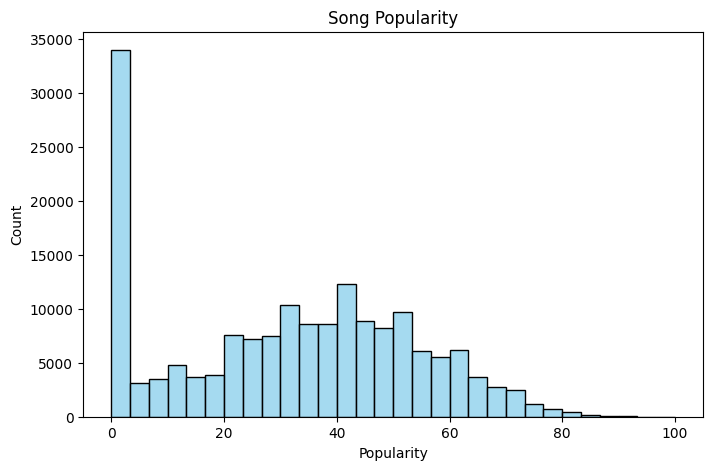

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(data['popularity'], bins=30, color='skyblue')
plt.title('Song Popularity')
plt.xlabel('Popularity')
plt.ylabel('Count')
plt.show()


This chart shows how the popularity of songs is distributed in the dataset. The x-axis (0 to 100) represents the popularity score, where 0 means a song is not popular at all and 100 means it is extremely popular on Spotify. The y-axis (0 to 35,000) represents the number of songs that fall within each popularity range. From the chart, we can see that most songs have a very low popularity score (close to 0), while only a smaller number of songs reach higher popularity scores (above 60). This suggests that only a small percentage of songs on Spotify become truly popular.

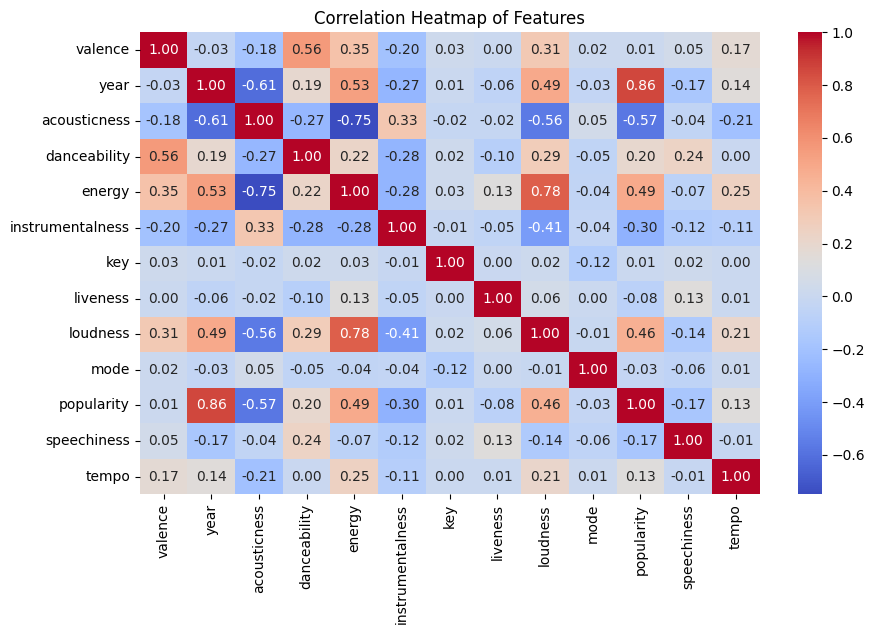

In [10]:
numeric_data = data.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


This heatmap shows the correlation between different song features and popularity. The values range from -1 to 1. A number closer to 1 means a strong positive relationship while a number closer to -1 means a strong negative relationship . A number near 0 means no clear relationship. From this heatmap, we see that year (0.86) has the strongest positive relationship with popularity, meaning newer songs tend to be more popular in this dataset. Features like energy (0.49) and loudness (0.46) also show a moderate positive relationship with popularity. On the other hand, acousticness (-0.57) is negatively correlated with popularity, which suggests that songs that are less acoustic (more electronic or energetic) tend to be more popular.

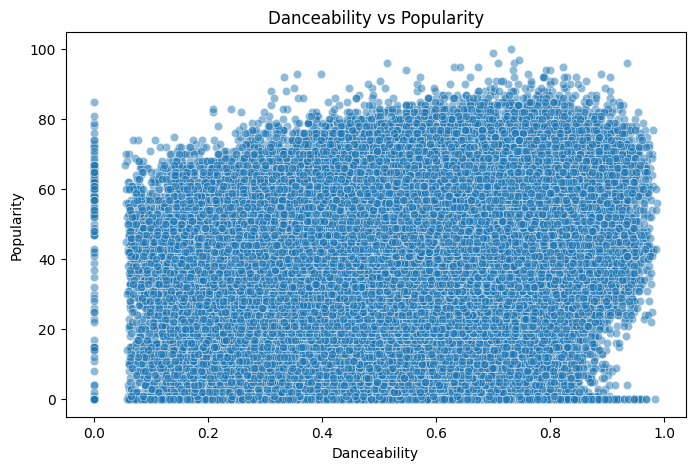

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='danceability', y='popularity', data=data, alpha=0.5)
plt.title('Danceability vs Popularity')
plt.xlabel('Danceability')
plt.ylabel('Popularity')
plt.show()



We can see that songs with higher danceability values (closer to 1) are spread across all popularity levels, but many popular songs have danceability between 0.5 and 0.9. There isn’t a perfect relationship, but the plot suggests that songs which are easier to dance to (higher danceability) tend to have a slightly better chance of being popular.

In [18]:
features = ['danceability', 'energy', 'loudness', 'tempo', 'valence']
X = data[features]
y = data['popularity']
X = X.dropna()
y = y.loc[X.index]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")


MSE: 323.13


This shows that while our model can recognize some patterns in the data, it cannot perfectly predict popularity because many other factors (like artist fame, marketing, or playlist placement) also play a big role in making a song popular.

In [15]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
})
print(coefficients)


        Feature  Coefficient
0  danceability    30.626858
1        energy    33.153373
2      loudness     0.610770
3         tempo     0.037587
4       valence   -27.055570


Energy (33.15) and danceability (30.63) have the strongest positive effects, suggesting that upbeat and energetic songs are generally more popular. Loudness and tempo have very small positive effects, meaning they don’t impact popularity as much. Valence (-27.05), which measures how happy or positive a song is, surprisingly has a negative effect, possibly because slower or sad songs can still become hits.

## Conclusion

From our analysis, we learned that a song’s popularity on Spotify is partly influenced by its audio features, but not completely determined by them. Features like energy and danceability show a strong positive relationship with popularity, meaning energetic and danceable songs are more likely to become hits. However, other features such as loudness and tempo have very little impact, and valence (happiness) even shows a negative effect, which suggests that sad or slower songs can still become popular. Our prediction model gave a Mean Squared Error of 323, meaning it can identify some trends but cannot fully predict popularity because factors like artist fame, marketing, and cultural trends play a big role. Overall, our project shows that while music features help explain popularity, there are many external influences that our dataset does not capture.



## Resources

Kaggle Dataset – https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-1921-2020-160k-tracks